![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Training and Prediction at Scale: Random Forests, Boosting and Deep Learning on GPUs

Spatial machine learning has an unusual shape. The training data are often small (a few hundred
soil samples, a few thousand labelled pixels), while the prediction covers every pixel of a large
raster: hundreds of millions of rows. Deep learning adds images that are too large to pass through
a network at once. This notebook uses `geolattice.distributed.ml` for each part: fitting random
forests and gradient boosting on the CPU and the GPU with spatial cross-validation, predicting a
soil organic carbon map over all 262 million pixels of the Great Plains, running a convolutional
network over a 1.7 GB aerial image in overlapping tiles, and training a network with distributed
data parallelism (DDP).

## Overview

### Where the work is

| Stage | Size here | Parallel pattern |
|---|---|---|
| Training a tree ensemble | 570 rows, 12 covariates | trees in parallel (random forest), split finding in parallel (boosting); a GPU helps for large tables |
| Cross-validation | 5 folds x 3 models | each fold is independent |
| Predicting a raster | 262 million pixels x 12 covariates | embarrassingly parallel: chunk by chunk, the model copied to each worker |
| Tiled inference of a CNN | 18,510 x 24,400 pixels | overlapping tiles; batches spread over GPUs |
| Training a network on large data | many batches | **data parallel**: each device holds a model replica, sees a shard of the data, and gradients are averaged after every step |

### Spatial cross-validation

Random k-fold cross-validation puts neighbouring samples into training and test folds, and with
spatially autocorrelated data it overstates accuracy. **Spatial cross-validation** groups samples
into spatial blocks (here 5 clusters of the sample coordinates) and holds out one block at a time,
which better reflects prediction into unsampled areas.

### Tiles, overlap and receptive fields

A convolutional network sees a neighbourhood around each output pixel (its **receptive field**).
At the edge of a tile part of that neighbourhood is missing and the network sees padding, so
predictions near tile edges differ from those in the middle. Overlapping tiles and keeping only
each tile's centre (**crop blending**) remove the seams when the overlap covers the receptive
field.

### Distributed data parallel

DDP starts one process per device. Each process builds the same model, reads a different shard
of each epoch's data (`DistributedSampler`), and after every backward pass the gradients are
averaged across processes (an all-reduce, NCCL on GPUs, Gloo on CPUs), so all replicas stay
identical. With `n` devices an epoch takes about `1/n` of the time.

## Machine Learning with GeoLattice

| Function | Does | CPU / GPU |
|---|---|---|
| `pdist.ml.fit(model, X, y, task=)` | fits `"rf"`, `"xgb"`, `"lgbm"` or any scikit-learn estimator; records the engine | scikit-learn, XGBoost, LightGBM / cuML random forest, XGBoost on CUDA |
| `pdist.ml.predict_raster(model, stack, proba=)` | predicts every pixel of a `(band, y, x)` raster chunk by chunk; NaN pixels stay NaN | the model's own device |
| `pdist.ml.predict_tiles(model, image, tile=, overlap=, blend=)` | runs a PyTorch model over a large image in overlapping tiles, one replica per GPU | PyTorch |
| `pdist.ml.train_ddp(fn, nprocs=, args=)` and `ddp_model(model, rank)` | launches DDP training, one process per device | NCCL / Gloo |

With an active cluster session, scikit-learn fits run on the cluster through joblib's Dask
backend and XGBoost on Dask arrays uses `xgboost.dask`.

### Learning objectives

1. Locate the expensive parts of a spatial machine learning workflow.
2. Fit random forest, XGBoost and LightGBM models on CPU and GPU, with spatial cross-validation.
3. Predict a 262 million pixel map chunk by chunk, and compare CPU and GPU prediction.
4. Predict class probabilities for every pixel.
5. Run a CNN over a 1.7 GB image in tiles and show that the tiles leave no seams.
6. Train a network with distributed data parallelism and check that the replicas agree.

### Data

| Dataset | Content |
|---|---|
| Great Plains soil organic carbon | 570 points with SOC (kg m-2) |
| Great Plains covariates | 12 continuous 90 m rasters (elevation, terrain, NDVI, climate, soil texture, K factor), 17,196 x 15,245 |
| Aerial image | `Data/08_remote_sensing/08_09_image_classification/Image_Fusion/HR/HR_Rural_July_14.tif`: 0.6 m, 18,510 x 24,400 pixels, red, green, blue and near-infrared, 1.7 GB |

### Contents

- Setup
- The training table
- Models on CPU and GPU with spatial cross-validation
- A soil carbon map of 262 million pixels
- Class probabilities for every pixel
- A CNN over a 1.7 GB image in tiles
- Distributed data parallel training
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import sys  # module search path for the DDP script
import torch  # deep learning
from sklearn.cluster import KMeans  # spatial blocks for cross-validation
from sklearn.metrics import mean_squared_error, r2_score  # accuracy measures


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done
    if torch.cuda.is_available():  # PyTorch work too
        torch.cuda.synchronize()  # block until done


def timed(fn):  # wall time and result of one call
    t = time.perf_counter(); out = fn(); sync(); return time.perf_counter() - t, out  # time it

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## The training table

The covariates are extracted at the 570 sampling points with `pdist.extract_values` (notebook 05);
the response is log SOC, because SOC is right-skewed.

In [2]:
soc = dd.gp_points()  # 570 sampling points
stack = dd.gp_stack()  # lazy (12, y, x) covariate stack on one grid
table = pdist.extract_values(soc, stack, name="v")  # one column per covariate
table = table.rename(columns=lambda c: c[2:] if c.startswith("v_") else c).dropna(subset=dd.PREDICTORS)  # tidy, complete rows
X = table[dd.PREDICTORS].to_numpy(np.float32)  # predictors
y = np.log(table.SOC.to_numpy())  # log SOC
xy = np.column_stack([table.geometry.x, table.geometry.y])  # coordinates
blocks = KMeans(5, random_state=0, n_init=10).fit_predict(xy)  # 5 spatial blocks
print(f"{len(table)} samples, {X.shape[1]} covariates; block sizes {np.bincount(blocks).tolist()}")  # sizes

561 samples, 12 covariates; block sizes [149, 98, 121, 81, 112]


## Models on CPU and GPU with spatial cross-validation

Each model is fitted five times, holding out one spatial block each time, on the CPU and on the
GPU where an implementation exists (cuML for the random forest, XGBoost's CUDA backend; LightGBM
here is CPU only).

In [3]:
models = {"rf": dict(n_estimators=500, max_features=0.5, random_state=0),  # random forest
          "xgb": dict(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8),  # boosting
          "lgbm": dict(n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8)}  # boosting
rows = []  # one row per model and target
for name, params in models.items():  # each model
    for c in (["cpu", "gpu"] if caps["gpus"] and name != "lgbm" else ["cpu"]):  # targets with an implementation
        pred = np.empty_like(y); fit_s = 0.0  # out-of-block predictions and fit time
        for b in range(5):  # hold out each block
            tr_, te = blocks != b, blocks == b  # split
            s, m = timed(lambda: pdist.ml.fit(name, X[tr_], y[tr_], task="regression", compute=c, **params))  # fit
            fit_s += s  # total fit time
            pred[te] = np.asarray(m.predict(X[te])).ravel()  # predict the held-out block
        rows.append({"model": name, "compute": c, "engine": m.geolattice_engine, "fit 5 folds (s)": fit_s,  # description
                     "RMSE (log)": mean_squared_error(y, pred) ** 0.5, "R2": r2_score(y, pred)})  # spatial CV accuracy
cv = pd.DataFrame(rows).set_index(["model", "compute"])  # table
cv.round(3)  # show

engine  fit 5 folds (s)  RMSE (log)     R2
model compute                                                  
rf    cpu           sklearn            2.321       0.710  0.436
      gpu              cuml           10.163       0.711  0.434
xgb   cpu       xgboost-cpu            0.417       0.707  0.441
      gpu      xgboost-cuda            1.096       0.698  0.454
lgbm  cpu      lightgbm-cpu            0.447       0.720  0.419

With 570 rows, training takes seconds everywhere and the GPU offers no advantage: there is too
little work to fill it, and copying data and launching kernels cost more than they save. The GPU
pays off for training on millions of rows (for example the pixels of a classified image), not for
point samples. The accuracies are modest, as is typical for soil carbon at the regional scale
under spatial cross-validation, and the three model types are close. The prediction step below is
where scale matters.

## A soil carbon map of 262 million pixels

The XGBoost model is refitted on all samples, once on each target, and `pdist.ml.predict_raster`
applies it to every pixel of the 12-band stack, chunk by chunk. Pixels where any covariate is
missing stay NaN.

In [4]:
final = {c: pdist.ml.fit("xgb", X, y, task="regression", compute=c, **models["xgb"])  # one model per target
         for c in (["cpu", "gpu"] if caps["gpus"] else ["cpu"])}  # targets
print(f"stack: {dict(stack.sizes)}, {dd.gb(stack.nbytes)}, {stack.data.npartitions} chunks")  # size
t, maps = {}, {}  # timings and maps
for c, m in final.items():  # each model
    lazy = pdist.ml.predict_raster(m, stack)  # lazy map, one task per chunk
    with dd.PeakMemory() as pm:  # watch memory
        t[c], soc_map = timed(lambda: lazy.compute())  # read covariates and predict every pixel
    print(f"{m.geolattice_engine}: {t[c]:.1f} s, peak memory {pm.peak_gb:.1f} GB, "  # time and memory
          f"{int(np.isfinite(soc_map.values).sum()) / t[c] / 1e6:.1f} million predicted pixels per second")  # throughput
    maps[c] = soc_map  # keep it
if len(maps) == 2:  # compare the two
    d = np.abs(maps["gpu"].values - maps["cpu"].values)  # difference in log SOC
    print(f"largest |GPU - CPU| difference: {np.nanmax(d):.2e} (log units)")  # agreement

stack: {'band': 12, 'y': 17196, 'x': 15245}, 12.58 GB, 864 chunks


xgboost-cpu: 35.3 s, peak memory 27.3 GB, 3.5 million predicted pixels per second


xgboost-cuda: 10.7 s, peak memory 29.7 GB, 11.5 million predicted pixels per second


largest |GPU - CPU| difference: 8.07e-01 (log units)


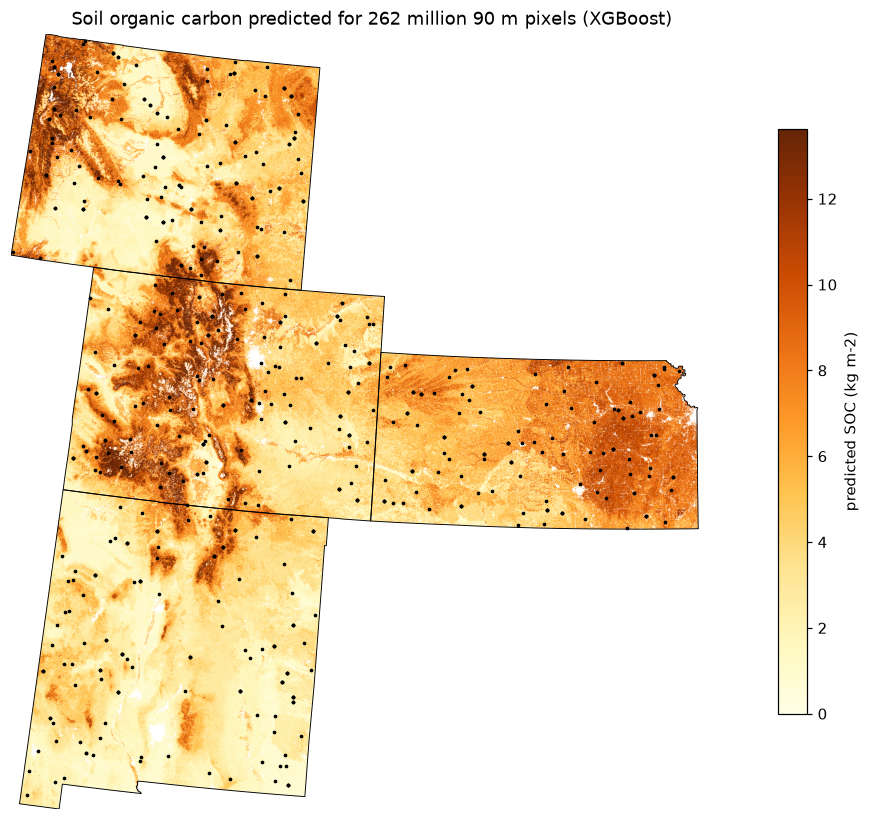

In [5]:
m = np.exp(maps["cpu"])  # back to kg m-2
q = dd.quicklook(m, 8)  # every 8th pixel for plotting
fig, ax = plt.subplots(figsize=(8.5, 8))  # one map
im = ax.imshow(q, cmap="YlOrBr", vmin=0, vmax=np.nanpercentile(q, 98), extent=dd.extent(q))  # map
soc.plot(ax=ax, markersize=2, color="k")  # sampling points
dd.gp_states().boundary.plot(ax=ax, color="k", lw=0.6)  # states
plt.colorbar(im, ax=ax, shrink=0.7, label="predicted SOC (kg m-2)")  # scale
ax.set_title("Soil organic carbon predicted for 262 million 90 m pixels (XGBoost)"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

Prediction on the GPU was several times faster than on 24 CPU cores, and the two maps agree to
float32 rounding: the GPU model receives each chunk as a CuPy array and predicts without copying
the model back and forth. The map follows the covariates the samples tracked in notebook 05:
higher carbon under the wetter, greener east and the cool, high mountains, low carbon on the warm
and dry southern plains.

## Class probabilities for every pixel

With `proba=True`, `predict_raster` returns one probability layer per class. Here SOC is split
into terciles (low, medium, high) and an XGBoost classifier gives each pixel's probability of
belonging to the high class; for speed this runs on a 4096 x 4096 window of Kansas.

{'class': 3, 'y': 4096, 'x': 4096} in 3.0 s; classes [0, 1, 2]; probabilities sum to 1: True


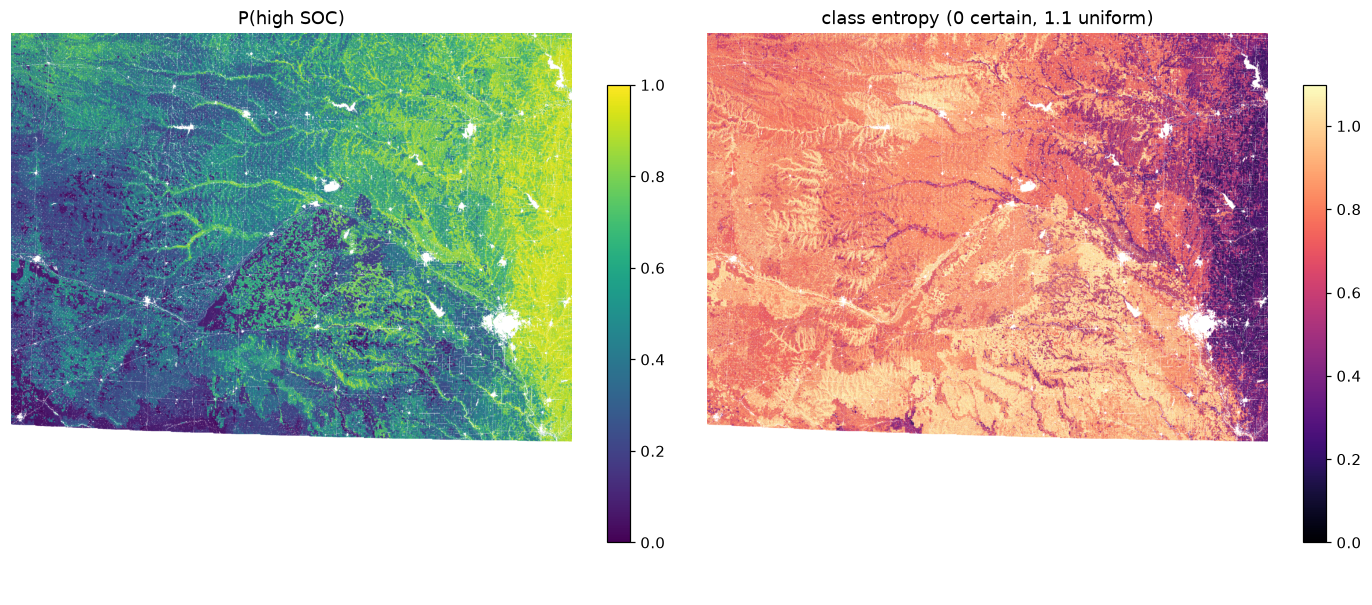

In [6]:
cls = np.digitize(y, np.quantile(y, [1 / 3, 2 / 3]))  # 0 low, 1 medium, 2 high
clf = pdist.ml.fit("xgb", X, cls, task="classification", compute="gpu" if caps["gpus"] else "cpu", n_estimators=300, max_depth=3, learning_rate=0.05)  # classifier
win = stack[:, 8000:12096, 9000:13096]  # central Kansas window
t0 = time.perf_counter(); prob = pdist.ml.predict_raster(clf, win, proba=True).compute(); s = time.perf_counter() - t0  # probabilities
print(f"{dict(prob.sizes)} in {s:.1f} s; classes {prob['class'].values.tolist()}; probabilities sum to 1:",  # shape
      bool(np.allclose(prob.sum("class").values[np.isfinite(prob[0].values)], 1, atol=1e-5)))  # check
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))  # two maps
im = ax[0].imshow(prob.sel({"class": 2}), cmap="viridis", vmin=0, vmax=1); ax[0].set_title("P(high SOC)"); plt.colorbar(im, ax=ax[0], shrink=0.8)  # high class
ent = -(prob * np.log(prob.clip(1e-9))).sum("class").where(np.isfinite(prob[0]))  # entropy: uncertainty of the class
im = ax[1].imshow(ent, cmap="magma", vmin=0, vmax=np.log(3)); ax[1].set_title("class entropy (0 certain, 1.1 uniform)"); plt.colorbar(im, ax=ax[1], shrink=0.8)  # uncertainty
[a.set_axis_off() for a in ax]; plt.tight_layout(); plt.show()  # draw

## A CNN over a 1.7 GB image in tiles

A tiny fully convolutional network learns to recognise vegetation from the red, green and blue
bands alone. Its labels come from the near-infrared band (NDVI above 0.3), so no manual labelling
is needed: the network must learn from colour and texture what the near-infrared band shows
directly. It is trained on random patches, then `pdist.ml.predict_tiles` runs it over the whole
image in 512 pixel tiles with 32 pixels of overlap.

In [7]:
import rioxarray  # read the image
img = rioxarray.open_rasterio(dd.DATA / "08_remote_sensing" / "08_09_image_classification" / "Image_Fusion" / "HR" / "HR_Rural_July_14.tif")  # lazy
with dd.timer("read the 4-band 0.6 m image"):  # 1.8 GB of uint8
    arr = img.values  # (4, 24400, 18510)
rgb = (arr[:3].astype(np.float32) / 255.0)  # inputs: red, green, blue in 0..1
ndvi = (arr[3].astype(np.float32) - arr[0]) / (arr[3].astype(np.float32) + arr[0] + 1e-6)  # labels from near-infrared and red
label = (ndvi > 0.3).astype(np.float32)  # vegetation mask
print(f"image {arr.shape}, {dd.gb(arr.nbytes)}; vegetation share {label.mean():.1%}")  # sizes

dev = "cuda" if torch.cuda.is_available() else "cpu"  # training device
torch.manual_seed(0); rng = np.random.default_rng(0)  # reproducible
net = torch.nn.Sequential(  # 4 convolutions: receptive field of 9 x 9 pixels
    torch.nn.Conv2d(3, 16, 3, padding=1), torch.nn.ReLU(), torch.nn.Conv2d(16, 16, 3, padding=1), torch.nn.ReLU(),
    torch.nn.Conv2d(16, 16, 3, padding=1), torch.nn.ReLU(), torch.nn.Conv2d(16, 2, 3, padding=1)).to(dev)  # 2 classes
opt = torch.optim.Adam(net.parameters(), lr=3e-3)  # optimizer
t0 = time.perf_counter()  # start
for step in range(300):  # 300 batches of 16 random 128 x 128 patches
    r = rng.integers(0, arr.shape[1] - 128, 16); c = rng.integers(0, arr.shape[2] - 128, 16)  # patch corners
    xb = torch.from_numpy(np.stack([rgb[:, i:i + 128, j:j + 128] for i, j in zip(r, c)])).to(dev)  # inputs
    yb = torch.from_numpy(np.stack([label[i:i + 128, j:j + 128] for i, j in zip(r, c)])).long().to(dev)  # labels
    loss = torch.nn.functional.cross_entropy(net(xb), yb)  # pixelwise loss
    opt.zero_grad(); loss.backward(); opt.step()  # update
print(f"trained on {dev} in {time.perf_counter() - t0:.0f} s, final loss {float(loss):.3f}")  # training

read the 4-band 0.6 m image: 7.28 s


image (4, 24400, 18510), 1.81 GB; vegetation share 54.4%


trained on cuda in 3 s, final loss 0.074


In [8]:
t = {}  # timings
with dd.PeakMemory() as pm:  # watch host memory
    t["whole image, tiles of 512, overlap 32"], out = timed(lambda: pdist.ml.predict_tiles(net, rgb, tile=512, overlap=32, batch_size=16))  # tiled inference
pred = out.argmax(0)  # predicted class per pixel
acc = (pred == label).mean()  # agreement with the NDVI labels
print(f"{out.shape[1]:,} x {out.shape[2]:,} pixels in {list(t.values())[0]:.0f} s, peak memory {pm.peak_gb:.0f} GB; "  # time and memory
      f"agreement with NDVI labels {acc:.1%}")  # accuracy
crop = rgb[:, 10000:12048, 8000:10048]  # a 2048 x 2048 crop
with torch.inference_mode():  # whole crop at once, no tiles
    whole = net(torch.from_numpy(crop[None]).to(dev)).float().cpu().numpy()[0]  # reference
tiled = pdist.ml.predict_tiles(net, crop, tile=256, overlap=32)  # the same crop in 81 tiles
naive = pdist.ml.predict_tiles(net, crop, tile=256, overlap=0)  # tiles without overlap
inner = (slice(None), slice(8, -8), slice(8, -8))  # away from the crop border
print(f"largest difference to whole-crop inference: overlap 32: {np.abs(tiled - whole)[inner].max():.1e}, "  # seamless
      f"no overlap: {np.abs(naive - whole)[inner].max():.2f}")  # seams

24,400 x 18,510 pixels in 13 s, peak memory 66 GB; agreement with NDVI labels 97.1%


largest difference to whole-crop inference: overlap 32: 0.0e+00, no overlap: 12.26


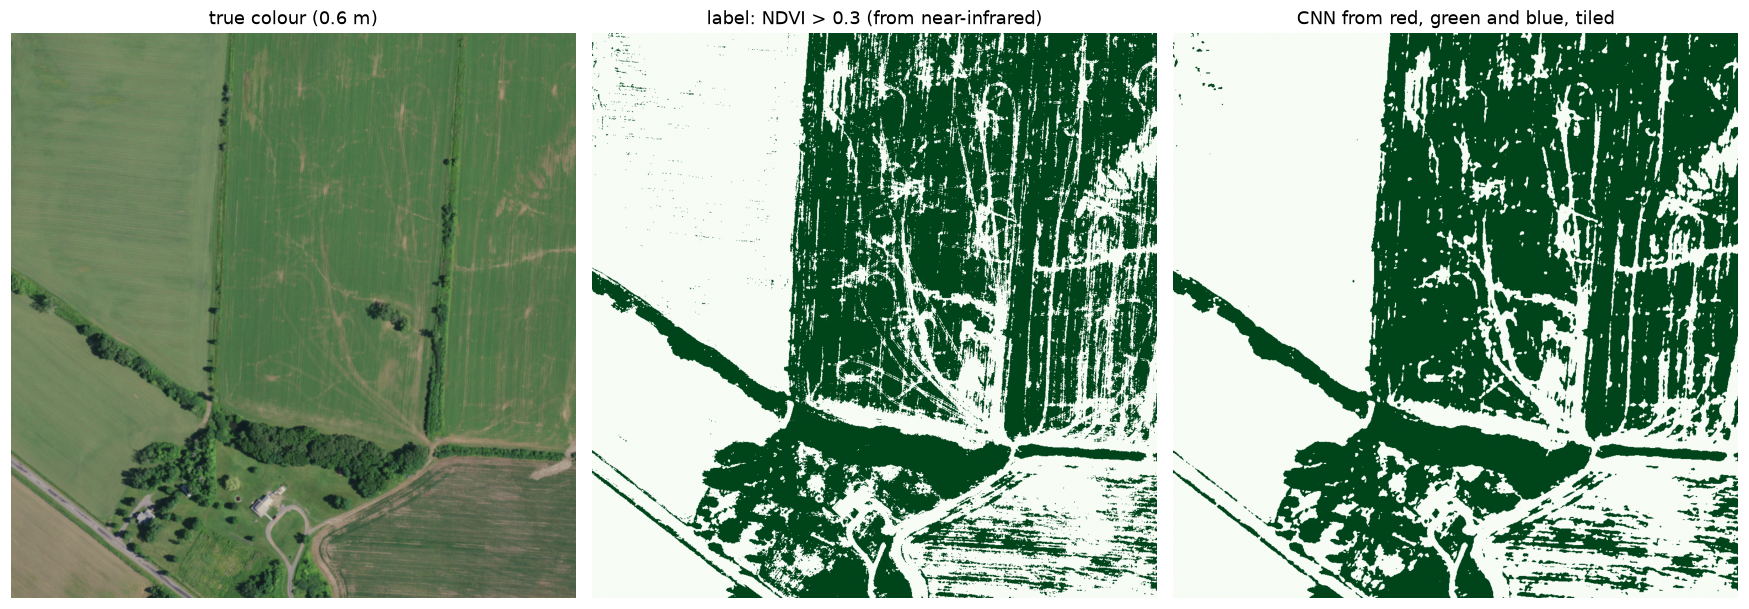

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))  # three panels
z = (slice(10000, 11024), slice(8000, 9024))  # 1024 x 1024 pixels (614 m)
ax[0].imshow(np.moveaxis(rgb[(slice(None),) + z], 0, -1)); ax[0].set_title("true colour (0.6 m)")  # image
ax[1].imshow(label[z], cmap="Greens"); ax[1].set_title("label: NDVI > 0.3 (from near-infrared)")  # labels
ax[2].imshow(pred[z], cmap="Greens"); ax[2].set_title("CNN from red, green and blue, tiled")  # prediction
[a.set_axis_off() for a in ax]; plt.tight_layout(); plt.show()  # draw

The tiled run covered all 452 million pixels in well under a minute on the GPU. With 32 pixels of
overlap the tiled result equals whole-crop inference to floating point rounding everywhere except
the crop's own border: the network's receptive field (9 x 9 pixels) fits inside the 16 pixels each
tile keeps as margin. Without overlap the tile edges see padding instead of their neighbours, and
the predictions there differ. The CNN reproduces the NDVI mask closely from colour alone; trees,
lawns and crops are green in the visible bands too.

Memory is the practical limit of this function: it holds the image, its padded copy and the
output in host memory (about 20 GB here). For larger images, run it window by window, or wrap it
in `pdist.raster.map_tiles` with an overlap.

## Distributed data parallel training

`pdist.ml.train_ddp` starts one process per device and runs a training function in each. The
function lives in `scripts/ddp_soc.py` (worker processes import it by name): it builds a small
network for log SOC, wraps it with `pdist.ml.ddp_model`, and gives each rank its own shard of the
data. With one GPU on this machine the GPU run uses one process; the CPU run uses two processes
with the Gloo backend, which shows the mechanics of several ranks.

In [10]:
sys.path.insert(0, str(Path("scripts").resolve()))  # make scripts/ddp_soc.py importable in the worker processes
import ddp_soc  # the training function
Xs = ((X - X.mean(0)) / X.std(0)).astype(np.float32)  # standardised predictors
runs = {}  # results per setup
if caps["gpus"]:  # one process on the GPU, NCCL
    t0 = time.perf_counter(); runs["1 GPU (NCCL)"] = pdist.ml.train_ddp(ddp_soc.train, nprocs=1, args=(Xs, y, 200)); runs["1 GPU (NCCL)"].append(time.perf_counter() - t0)  # train
t0 = time.perf_counter(); runs["2 CPU processes (Gloo)"] = pdist.ml.train_ddp(ddp_soc.train, nprocs=2, backend="gloo", args=(Xs, y, 200)); runs["2 CPU processes (Gloo)"].append(time.perf_counter() - t0)  # train
for name, r in runs.items():  # summarise
    *ranks, secs = r  # rank results and time
    print(f"{name}: {secs:.0f} s | " + " | ".join(f"rank {k['rank']} on {k['device']}: {k['rows']} rows, final loss {k['history'][-1]:.3f}, "
                                                    f"weights checksum {k['weights_checksum']:.6f}" for k in ranks))  # per rank

/home/zia207/Github/GeoLattice/Tutorials/notebooks/08_distributed_spatial/scripts/ddp_soc.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  total += float(loss) * len(xb)


/home/zia207/Github/GeoLattice/Tutorials/notebooks/08_distributed_spatial/scripts/ddp_soc.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  total += float(loss) * len(xb)
/home/zia207/Github/GeoLattice/Tutorials/notebooks/08_distributed_spatial/scripts/ddp_soc.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  total += float(loss) * len(xb)


1 GPU (NCCL): 7 s | rank 0 on cuda:0: 561 rows, final loss 0.085, weights checksum -33.331352
2 CPU processes (Gloo): 5 s | rank 0 on cpu: 281 rows, final loss 0.101, weights checksum -21.550788 | rank 1 on cpu: 281 rows, final loss 0.110, weights checksum -21.550788


Each of the two CPU ranks trained on half of the rows per epoch, yet both ended with exactly the
same weights (the checksums match): DDP averages the gradients after every step, so the replicas
never diverge. The times are dominated by starting the processes and by communication; a network
this small on 570 rows gains nothing from parallel training. DDP pays off when each step is
expensive: large networks, large images, many batches. On a machine with `n` GPUs,
`train_ddp(fn)` without `nprocs` starts one process per GPU with NCCL, and the same function runs
unchanged; on a cluster `torchrun` or a SLURM job array starts the processes instead.

## Summary and exercises

- In spatial machine learning, training data are often small and prediction is large. With 570
  samples the GPU did not speed up training; it sped up prediction of 262 million pixels several
  times, with results identical to the CPU's.
- Spatial cross-validation by blocks gave a realistic R2 for regional soil carbon.
- `predict_raster` predicts values or class probabilities chunk by chunk; NaN pixels stay NaN.
- `predict_tiles` ran a CNN over a 1.7 GB image; with an overlap at least twice the receptive-field
  radius the tiles left no seams.
- `train_ddp` and `ddp_model` keep replicas identical by averaging gradients; parallel training
  pays off only when each step is expensive.

**Exercises**

1. Replace the random spatial blocks with 10 blocks and with leave-one-state-out cross-validation.
   How do RMSE and R2 change?
2. Predict the SOC map with the random forest on the GPU (cuML) and compare speed and map with
   XGBoost.
3. Run `predict_tiles` with `tile=256` and `tile=1024`. How do time and GPU memory change?
4. Add a fifth convolution to the CNN. What is the receptive field now, and what overlap removes
   the seams?